# 동결 HuBERT와 논문 CNN: 3가지 시간 풀링 비교
**Google Colab · GPU · PyTorch · Transformers**

Javanmardi, Kadiri & Alku (2024), *Pre-trained models for detection and severity level classification of dysarthria from speech*, Speech Communication 158, 103047. [논문 DOI](https://doi.org/10.1016/j.specom.2024.103047).

이 노트북은 **논문 방법의 재구현 + 사용자 데이터/분할을 이용한 확장 실험**입니다. 원 논문의 수치 재현이나 실행 완료를 주장하지 않습니다. 저장된 실행 결과는 비어 있으며 실제 실행에서만 수치를 생성합니다.

### 실행 순서
1. Colab에서 **런타임 → 런타임 유형 변경 → GPU**를 선택하고 설치 셀 실행.
2. Drive를 mount한 뒤 설정 셀의 `DATA_ROOT`, `ZIP_PATH`를 확인합니다. 기존 노트북에서 확인한 기본 경로를 사용하며 ZIP을 Colab 로컬 공간에 풉니다. 공유 폴더는 내 드라이브에 바로가기를 추가해야 mount 경로로 보일 수 있습니다. URL의 폴더 ID는 파일시스템 경로가 아닙니다.
3. 원본 WAV와 환자 라벨을 검증한 뒤 나머지 셀을 순서대로 실행합니다. 분석용 CSV나 WavLM 캐시를 HuBERT 음성 입력으로 대체하지 않습니다.
4. 각 조합의 학습과 층 선택이 끝난 뒤 test 평가 셀 실행. 결과는 Drive의 새로운 실행 폴더에 저장됩니다.

**확인된 데이터 상황:** 제공 Drive 폴더는 `ALS_voice_analysis_20260921_075155`입니다. `03_file_level_features.csv`에 잘못 추론된 patient_id와 빈 label이 있어 그 값을 재사용하지 않습니다. 원본 메타데이터 기록은 `task1/sand_task_1.xlsx`의 `ID`, `Class` 열을 가리킵니다. 기존 `ALS_Model_Experiment_02.ipynb`에서 원본 ZIP 경로와 master sheet를 확인해 기본 설정에 반영했습니다. `Class 5 → HC`, `Class 1–4 → ALS`는 기존 노트북의 매핑을 따릅니다. Class 1–4를 원 논문의 중증도 등급으로 간주하지 않습니다. ALS/HC 분류는 원 논문의 UA-Speech/TORGO 구음장애 분류와 다른 데이터 과제입니다.


## 1. 재현 범위와 비교 설계
| 항목 | 논문 | 이 노트북 |
|---|---|---|
| 특징 추출기 | ASR fine-tuned HuBERT, 24층, 1024차원; 정확한 checkpoint ID 미기재 | 사용자 지정 `facebook/hubert-large-ls960-ft`, 전체 동결 |
| 메인 모델 | 논문은 SVM/CNN 분류기 사용 | `HuBERT+MLP`: 동결 특징 → 2개 FC 층, 추가 비교군 |
| CNN 비교군 | 3 × Conv → BN → ReLU → Flatten → 2 × FC | `HuBERT+CNN`: 동일 구조, 미기재 폭/커널 등은 아래 명시 |
| 풀링 | 시간축 평균만 사용; pooling 우열 실험 없음 | mean(논문 기준), max, mean+std |
| 분할 | detection LOSO, severity 화자 조합 반복 | 환자 단위 stratified 70/15/15, seed 42; 정수 환자 수 반올림 |
| 정규화 | train 통계 z-score | 각 층·pooling의 train 통계로만 fit |
| 학습 | Adam, lr 0.001, batch 64, 최대 100 epoch, patience 20 | 동일; early stopping 기준 val loss는 구현 선택 |
| 출력 | 층별 ACC, 탐지 ACC/SE/SP/F1/EER, 혼동행렬, 중증도별 ACC, 오분류 | 같은 구성 요소 + 모든 2모델×3pooling 조합 |

CNN은 원시 음성을 직접 학습하는 모델이 아니라 **시간 풀링한 HuBERT 벡터를 입력받는 분류기**입니다. Conv1d는 시간축이 아닌 풀링 이후 특징 축에 적용합니다. HuBERT 자체가 분류기는 아니므로 메인 모델에는 MLP 분류기를 붙였습니다. Jev는 사용자 요청에 따라 제외했으며 어떤 API 호출도 하지 않습니다.

논문의 HuBERT-1…25에 대응하도록 `paper_layer = hidden_state_index + 1`을 사용합니다. index 0은 첫 Transformer 앞 표현, 1…24는 각 Transformer 출력입니다. Transformers의 hidden_states를 이 대응으로 사용한다는 구현 가정도 기록합니다.

## 2. Pooling 선정 근거
- **Temporal mean (논문 기준)**: 모든 프레임의 평균. 논문 §2.1.2의 방법이며, 논문이 여러 pooling 중 최고라고 검증한 것은 아닙니다.
- **Temporal max (추가)**: 각 특징의 시간축 최댓값. 짧게 나타나는 강한 특징 반응이 평균에서 희석되는지 비교합니다. 잡음/이상값에 민감할 수 있습니다.
- **Temporal statistics (추가)**: 시간축 평균과 표준편차(population std, correction=0)를 연결. 평균 외에 발화 내 변동성을 보존합니다. 구음장애 관련 특징 변동을 포착한다는 가설을 시험하며 성능 향상을 보장하지 않습니다. 차원은 2048로 증가합니다.

추가 두 방법도 순서를 직접 모델링하지 않는 시간축 집계입니다. 둘 다 학습 파라미터가 없어서 backbone 동결을 유지하며 동일 특징에서 비교할 수 있습니다. padding 프레임은 사용하지 않습니다(음성 1개씩 추출).


In [ ]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import json, re, gc, random, hashlib, shutil, platform, importlib.metadata, zipfile
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import librosa, soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_curve
from scipy.optimize import brentq
from scipy.interpolate import interp1d
from IPython.display import display, Markdown
from tqdm.auto import tqdm
from transformers import HubertModel, AutoFeatureExtractor
from huggingface_hub import model_info

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Colab 런타임을 GPU로 변경하세요.'
print('PyTorch:', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130 | GPU: Tesla T4


In [ ]:
from google.colab import drive
mount_result = drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# 폴더 URL: https://drive.google.com/drive/folders/1PfZDFjx1PwK4wVLKJlZPa3BeIKdsoyDp
DATA_ROOT = Path('/content/drive/MyDrive/2026_2_INSIGHT/ALS_RESULTS/ALS_voice_analysis_20260921_075155')
# 출처: 기존 ALS_Model_Experiment_02.ipynb 설정/메타데이터 셀
ZIP_PATH = Path('/content/drive/MyDrive/2026_2_INSIGHT/SAND_Challenge_task1_dataset.zip')
EXTRACT_ROOT = Path('/content/hubert_sand_raw')
AUDIO_ROOT = EXTRACT_ROOT / 'task1'
LABELS_PATH = AUDIO_ROOT / 'sand_task_1.xlsx'
# 표준 manifest가 있으면 지정: path,speaker_id,label 필수; dataset,severity 선택.
# path는 AUDIO_ROOT 기준 상대 경로 또는 절대 경로. CSV만 사용.
MANIFEST_PATH = None
DATASET_NAME = 'ALS_HC'
ID_COLUMN, LABEL_COLUMN = 'ID', 'Class'
LABEL_SHEET = 'SAND - TRAINING set - Task 1'
SEVERITY_COLUMN = None  # 임상적으로 확인된 중증도 열이 있을 때만 지정
LABEL_MAP = {'1':1, '2':1, '3':1, '4':1, '5':0, 'HC':0, 'ALS':1}  # 기존 노트북에서 확인
# SAND 원본 Class=5만 HC, 1–4는 ALS. 모델 target은 0=HC, 1=ALS.
# 다른 데이터로 바꾸면 LABEL_MAP과 LABEL_SHEET도 변경하세요.
CLASS_NAMES = ['HC', 'ALS']
SEVERITY_ORDER = []  # 예: ['very_low', 'low', 'medium', 'high']; 실제 라벨 순서로 입력

SEED = 42                  # 구현 선택
MODEL_ID = 'facebook/hubert-large-ls960-ft'
MODEL_REVISION = 'main'     # 최초 실행 때 commit SHA로 해석하여 실행 기록에 저장
HIDDEN_INDICES = list(range(25))  # 전체 층 곡선: 0..24, 총 25개
POOLINGS = ['mean', 'max', 'mean_std']
HEADS = ['MLP', 'CNN']
BATCH_SIZE = 64
MAX_EPOCHS = 20
PATIENCE = 3
LR = 0.0005
WEIGHT_DECAY = 1e-3
DROPOUT = 0.5
CHUNK_SECONDS = None       # 기본: 발화 전체; OOM일 때만 20.0 등으로 변경
# chunk를 켜면 모든 음성을 보존하지만 Transformer 문맥이 달라지는 확장 실험입니다.
MIN_AUDIO_SAMPLES = 400    # HuBERT convolution receptive field; 짧은 음성은 오류로 보고
JEV_API_KEY = 'Enter your jev api for here'  # 미사용: Jev 제외, 저장/출력/전송하지 않음

assert len(CLASS_NAMES) == 2
assert sorted(set(HIDDEN_INDICES)) == HIDDEN_INDICES and all(0 <= x <= 24 for x in HIDDEN_INDICES)
if CHUNK_SECONDS is not None: assert CHUNK_SECONDS >= 1.0
seed_everything(SEED)
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUT = DATA_ROOT / 'HUBERT_PAPER_REPRODUCTION' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
CACHE_ROOT = DATA_ROOT / 'HUBERT_PAPER_FEATURE_CACHE_V1'
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
print('Output:', OUT)


Output: /content/drive/MyDrive/2026_2_INSIGHT/ALS_RESULTS/ALS_voice_analysis_20260921_075155/HUBERT_PAPER_REPRODUCTION/20261005T080540_357849Z


## 3. 원본 파일과 라벨 검증
공유된 폴더는 분석 산출물 폴더입니다. **기존 노트북에서 확인한 SAND ZIP을 아래 셀에서 압축 해제합니다.** 원본 위치가 이동했다면 `ZIP_PATH`를 수정하세요. 이미 풀린 음성을 쓰려면 `ZIP_PATH=None`으로 설정하고 `AUDIO_ROOT`, `LABELS_PATH`를 수정하세요. 자동으로 다른 프로젝트의 파일을 찾아 학습하지 않습니다.

`ID000_phonationA.wav` → 환자 `ID000`으로 연결합니다. 동일 ID의 모든 task·recording은 같은 split으로 보냅니다. 기본은 전체 272명 라벨이 있던 `SAND - TRAINING set - Task 1` master sheet를 사용합니다. 다른 데이터에서 `LABEL_SHEET=None`이면 같은 ID가 여러 sheet에 반복될 때 라벨 일치를 검사합니다. 이 노트북에서는 요청한 새 분할을 사용하므로 기존 training/test 폴더 구분을 유지하지 않습니다.

`__MACOSX`, `._*` 파일은 제외합니다. 라벨 불명, ID 불명, 충돌, 중복 음성, 손상 파일은 로그를 저장한 후 중단하며 임의로 버리거나 라벨을 추측하지 않습니다. 범용 데이터에는 표준 manifest를 권장합니다.


In [ ]:
# mount된 Drive의 원본 ZIP을 사용. 다운로드/API 키 불필요.
if MANIFEST_PATH is None and ZIP_PATH is not None:
    if not ZIP_PATH.is_file():
        raise FileNotFoundError(f'기존 노트북의 ZIP이 현재 위치에 없습니다: {ZIP_PATH}. ZIP_PATH를 수정하세요.')
    fingerprint={'path':str(ZIP_PATH),'size':ZIP_PATH.stat().st_size,'mtime':ZIP_PATH.stat().st_mtime_ns}
    marker=EXTRACT_ROOT/'extraction_complete.json'
    reuse=marker.exists() and json.loads(marker.read_text())==fingerprint
    if not reuse:
        if EXTRACT_ROOT.exists() and any(EXTRACT_ROOT.iterdir()):
            raise ValueError('기존 추출 폴더와 ZIP fingerprint가 다릅니다. EXTRACT_ROOT를 새 경로로 지정하세요.')
        EXTRACT_ROOT.mkdir(parents=True,exist_ok=True)
        with zipfile.ZipFile(ZIP_PATH) as archive:
            entries=[z for z in archive.infolist() if not z.is_dir() and '__MACOSX' not in Path(z.filename).parts
                     and not Path(z.filename).name.startswith('._') and Path(z.filename).suffix.lower() in {'.wav','.flac','.xlsx'}]
            required=sum(z.file_size for z in entries)
            if shutil.disk_usage(EXTRACT_ROOT).free < required + 1024**3:
                raise RuntimeError('Colab 로컬 디스크에 압축 해제 공간이 부족합니다.')
            for z in tqdm(entries,desc='Extract original audio and labels'):
                dest=(EXTRACT_ROOT/z.filename).resolve()
                if not dest.is_relative_to(EXTRACT_ROOT.resolve()): raise ValueError('ZIP 경로가 추출 폴더 밖을 가리킵니다.')
                dest.parent.mkdir(parents=True,exist_ok=True)
                with archive.open(z) as src, open(dest,'wb') as dst: shutil.copyfileobj(src,dst)
        marker.write_text(json.dumps(fingerprint,indent=2))
    print('Raw audio:',AUDIO_ROOT,'| Metadata:',LABELS_PATH)


Extract original audio and labels:   0%|          | 0/2177 [00:00<?, ?it/s]

Raw audio: /content/hubert_sand_raw/task1 | Metadata: /content/hubert_sand_raw/task1/sand_task_1.xlsx


In [ ]:
def canonical_id(value):
    text = str(value).strip()
    m = re.fullmatch(r'(?:ID)?(\d+)(?:\.0)?', text, flags=re.I)
    return f'ID{int(m.group(1)):03d}' if m else text

def read_labels(path):
    if not path.is_file():
        raise FileNotFoundError(f'원본 라벨 파일이 없습니다: {path}. LABELS_PATH를 수정하세요.')
    tables = pd.read_excel(path, sheet_name=None, dtype=str) if path.suffix.lower() == '.xlsx' else {'csv': pd.read_csv(path, dtype=str)}
    if LABEL_SHEET is not None and path.suffix.lower() == '.xlsx':
        if LABEL_SHEET not in tables: raise ValueError(f'지정 sheet 없음: {LABEL_SHEET}; 실제: {list(tables)}')
        tables = {LABEL_SHEET: tables[LABEL_SHEET]}
    relevant = [t for t in tables.values() if {ID_COLUMN, LABEL_COLUMN}.issubset(t.columns)]
    if not relevant: raise ValueError(f'필수 열 {ID_COLUMN}, {LABEL_COLUMN}을 찾지 못했습니다.')
    cols = [ID_COLUMN, LABEL_COLUMN] + ([SEVERITY_COLUMN] if SEVERITY_COLUMN else [])
    labels = pd.concat([t[cols] for t in relevant], ignore_index=True)
    labels = labels.dropna(subset=[ID_COLUMN, LABEL_COLUMN]).copy()
    labels['speaker_id'] = labels[ID_COLUMN].map(canonical_id)
    raw = labels[LABEL_COLUMN].str.strip().str.upper().str.replace(r'^(\d+)\.0$', r'\1', regex=True)
    labels['label'] = raw.map(LABEL_MAP)
    if labels['label'].isna().any():
        raise ValueError(f'LABEL_MAP에 없는 실제 Class 값: {sorted(raw[labels.label.isna()].unique())}. 의미 확인 후 map을 수정하세요.')
    if SEVERITY_COLUMN: labels['severity'] = labels[SEVERITY_COLUMN].str.strip()
    check = ['label'] + (['severity'] if SEVERITY_COLUMN else [])
    if (labels.groupby('speaker_id')[check].nunique(dropna=False) > 1).any().any():
        raise ValueError('동일 환자 ID의 라벨이 sheet 간 충돌합니다. 원본 메타데이터를 확인하세요.')
    return labels[['speaker_id'] + check].drop_duplicates('speaker_id')

def build_manifest():
    if MANIFEST_PATH is not None:
        frame = pd.read_csv(MANIFEST_PATH, dtype={'speaker_id': str})
        if not {'path', 'speaker_id', 'label'}.issubset(frame):
            raise ValueError('manifest 필수 열: path, speaker_id, label')
        frame['path'] = frame['path'].map(lambda p: str(Path(p) if Path(p).is_absolute() else AUDIO_ROOT / p))
        if not frame['label'].isin([0, 1]).all(): raise ValueError('manifest label은 0=대조군, 1=환자여야 합니다.')
    else:
        if not AUDIO_ROOT.is_dir():
            raise FileNotFoundError(f'원본 음성 폴더가 없습니다: {AUDIO_ROOT}. 분석 CSV는 음성을 대체할 수 없습니다.')
        labels = read_labels(LABELS_PATH)
        paths = sorted(p for p in AUDIO_ROOT.rglob('*') if p.suffix.lower() in {'.wav', '.flac'} and '__MACOSX' not in p.parts and not p.name.startswith('._'))
        if not paths: raise ValueError('WAV/FLAC 원본이 없습니다. AUDIO_ROOT를 확인하세요.')
        rows = []
        for p in paths:
            m = re.search(r'(?i)(?:^|_)(ID\d+)(?:_|$)', p.stem)
            rows.append({'path': str(p), 'speaker_id': canonical_id(m.group(1)) if m else None})
        frame = pd.DataFrame(rows).merge(labels, on='speaker_id', how='left', validate='many_to_one')
    if 'dataset' not in frame: frame['dataset'] = DATASET_NAME
    if frame[['path', 'speaker_id', 'label', 'dataset']].isna().any().any():
        frame.to_csv(OUT / 'manifest_incomplete.csv', index=False)
        raise ValueError('ID/label/dataset 누락. manifest_incomplete.csv와 원본 라벨을 확인하세요.')
    frame['path'] = frame.path.map(lambda p: str(Path(p).resolve()))
    frame = frame.drop_duplicates('path', keep='first').copy()
    frame['label'] = frame.label.astype(int)
    frame['subject'] = frame.dataset.astype(str) + '::' + frame.speaker_id.astype(str)
    if (frame.groupby('subject').label.nunique() != 1).any(): raise ValueError('환자별 탐지 라벨이 충돌합니다.')
    return frame.sort_values(['dataset', 'speaker_id', 'path']).reset_index(drop=True)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''): h.update(block)
    return h.hexdigest()

manifest = build_manifest()
checks = []
for row in tqdm(manifest.itertuples(), total=len(manifest), desc='Audio validation'):
    try:
        audio, sr = sf.read(row.path, dtype='float32', always_2d=True)
        if not np.isfinite(audio).all() or len(audio) == 0: raise ValueError('비어 있거나 비유한 음성')
        if len(audio) / sr * 16000 < MIN_AUDIO_SAMPLES: raise ValueError('HuBERT에 비해 너무 짧은 음성')
        checks.append({'sha256': sha256_file(row.path), 'duration_sec': len(audio) / sr, 'source_sr': sr, 'error': ''})
    except Exception as exc: checks.append({'sha256': '', 'duration_sec': np.nan, 'source_sr': np.nan, 'error': str(exc)})

manifest = pd.concat([manifest, pd.DataFrame(checks)], axis=1)
manifest.to_csv(OUT / 'audio_audit.csv', index=False)
if manifest.error.ne('').any(): raise ValueError('audio_audit.csv의 오류를 수정한 뒤 다시 실행하세요. 모든 조합의 표본을 동일하게 유지합니다.')

manifest = manifest.drop_duplicates('sha256', keep='first').reset_index(drop=True)
manifest['sample_id'] = manifest.sha256

print('환자 수:', manifest.subject.nunique(), '| 음성 수:', len(manifest))
display(manifest.groupby(['dataset', 'label']).agg(subjects=('subject', 'nunique'), recordings=('path', 'size')))

Audio validation:   0%|          | 0/2176 [00:00<?, ?it/s]

환자 수: 271 | 음성 수: 2164


subjects  recordings
dataset label                      
ALS_HC  0           106         848
        1           165        1316

In [ ]:
def make_splits(frame):
    df=frame.copy()
    if 'severity' in df:
        df['severity']=df.severity.replace(r'^\s*$',np.nan,regex=True)
        if (df.groupby('subject').severity.nunique(dropna=False)>1).any():
            raise ValueError('동일 환자의 severity가 충돌합니다.')
    subjects=df.drop_duplicates('subject').copy()
    subjects['stratum']=subjects.label.astype(str)
    # 중증도 라벨이 있으면 severity도 분할 계층에 포함. 누락값은 별도 계층.
    if 'severity' in subjects:
        subjects.loc[subjects.label.eq(1),'stratum'] += ':' + subjects.loc[subjects.label.eq(1),'severity'].fillna('missing').astype(str)
    mapping={}
    for dataset,s in subjects.groupby('dataset',sort=True):
        try:
            train, rest=train_test_split(s,test_size=0.30,random_state=SEED,stratify=s.stratum)
            val,test=train_test_split(rest,test_size=0.50,random_state=SEED,stratify=rest.stratum)
        except ValueError as exc:
            raise ValueError(f'{dataset}: 환자/클래스 수가 70/15/15 층화 분할에 부족합니다. 표본을 늘리거나 실험 설계를 수정하세요. 임의 fallback 없음. {exc}') from exc
        for name,part in [('train',train),('val',val),('test',test)]:
            if set(part.stratum)!=set(s.stratum): raise ValueError(f'{dataset}/{name}에서 클래스 누락')
            mapping.update(dict.fromkeys(part.subject,name))
    df['split']=df.subject.map(mapping)
    groups=[set(df.loc[df.split.eq(s),'subject']) for s in ['train','val','test']]
    assert not any(groups[i]&groups[j] for i in range(3) for j in range(i+1,3))
    assert df.split.notna().all()
    return df

manifest=make_splits(manifest)
manifest.to_csv(OUT/'split_manifest.csv',index=False)
SPLIT_HASH=hashlib.sha256(manifest[['sample_id','subject','label','split']].to_csv(index=False).encode()).hexdigest()
summary=manifest.groupby(['dataset','split']).agg(subjects=('subject','nunique'),recordings=('path','size'))
summary['subject_fraction']=summary.subjects / summary.groupby(level=0).subjects.transform('sum')
summary['recording_fraction']=summary.recordings / summary.groupby(level=0).recordings.transform('sum')
display(summary)
print('70/15/15는 환자 수 기준이며 반올림으로 차이가 날 수 있습니다. 음성 개수 비율은 다를 수 있습니다.')


subjects  recordings  subject_fraction  recording_fraction
dataset split                                                            
ALS_HC  test         41         328          0.151292            0.151571
        train       189        1510          0.697417            0.697782
        val          41         326          0.151292            0.150647

70/15/15는 환자 수 기준이며 반올림으로 차이가 날 수 있습니다. 음성 개수 비율은 다를 수 있습니다.


## 4. 동결 HuBERT 특징 추출과 캐시
모든 HuBERT 파라미터를 `requires_grad_(False)`로 설정하고 `eval()` + `inference_mode()`에서 음성 1개씩 처리합니다. CTC 텍스트 출력층은 사용하지 않습니다. 원본을 mono/16kHz로 변환하고 체크포인트의 feature extractor로 정규화합니다.

기본은 발화 전체를 처리합니다. GPU 메모리 부족 시 `CHUNK_SECONDS=20.0` 등으로 변경하고 새 실행을 시작하세요. Chunk 모드에서도 끝부분을 버리지 않으며, 프레임 개수로 가중한 평균/분산과 전역 max를 계산합니다. 단, chunk 경계에서 문맥과 프레임 격자가 달라지므로 논문과 동일한 특징은 아닙니다. OOM이 발생해도 임의 crop이나 자동 chunk 전환을 하지 않습니다.

캐시는 음성 SHA256, 모델 revision, 층, chunk 설정, 라이브러리 버전으로 구분합니다. 기존 WavLM 또는 다른 모델 캐시는 사용하지 않습니다. 25개 층을 추출한 뒤 2×3×25=150개 분류기를 각 데이터셋·과제별로 학습하므로 시간이 걸립니다.


In [ ]:
RESOLVED_REVISION=model_info(MODEL_ID,revision=MODEL_REVISION).sha
extractor=AutoFeatureExtractor.from_pretrained(MODEL_ID,revision=RESOLVED_REVISION)
backbone=HubertModel.from_pretrained(MODEL_ID,revision=RESOLVED_REVISION).to(DEVICE)
backbone.requires_grad_(False); backbone.eval()
assert not any(p.requires_grad for p in backbone.parameters())
assert backbone.config.hidden_size == 1024 and backbone.config.num_hidden_layers == 24
FEATURE_SPEC={'model':MODEL_ID,'revision':RESOLVED_REVISION,'layers':HIDDEN_INDICES,
              'chunk_seconds':CHUNK_SECONDS,'sr':16000,'dtype':'float32',
              'transformers':importlib.metadata.version('transformers'),
              'librosa':librosa.__version__,'torch':torch.__version__,'version':1}
FEATURE_HASH=hashlib.sha256(json.dumps(FEATURE_SPEC,sort_keys=True).encode()).hexdigest()[:20]
CACHE=CACHE_ROOT/FEATURE_HASH; CACHE.mkdir(exist_ok=True)
(CACHE/'feature_spec.json').write_text(json.dumps(FEATURE_SPEC,indent=2))
print('Resolved model revision:',RESOLVED_REVISION)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

Resolved model revision: ece5fabbf034c1073acae96d5401b25be96709d8


In [ ]:
def pool_hidden_chunks(chunks):
    # chunks: list of [layers, time, channels] numpy arrays; correction=0.
    n=sum(x.shape[1] for x in chunks)
    if n<1: raise ValueError('유효 프레임이 없습니다.')
    sums=sum(x.astype(np.float64).sum(axis=1) for x in chunks)
    squares=sum(np.square(x.astype(np.float64)).sum(axis=1) for x in chunks)
    mean=sums/n
    std=np.sqrt(np.maximum(squares/n - mean**2,0))
    maximum=np.maximum.reduce([x.max(axis=1) for x in chunks])
    return {'mean':mean.astype('float32'),'max':maximum.astype('float32'),
            'mean_std':np.concatenate([mean,std],axis=-1).astype('float32')}

def audio_segments(audio):
    if CHUNK_SECONDS is None: return [audio]
    width=int(CHUNK_SECONDS*16000)
    pieces=[audio[i:i+width] for i in range(0,len(audio),width)]
    if len(pieces)>1 and len(pieces[-1])<MIN_AUDIO_SAMPLES:
        pieces[-2]=np.concatenate([pieces[-2],pieces[-1]]); pieces.pop()
    return pieces

@torch.inference_mode()
def extract_one(path):
    audio,sr=sf.read(path,dtype='float32',always_2d=True)
    audio=audio.mean(axis=1)
    if sr!=16000: audio=librosa.resample(audio,orig_sr=sr,target_sr=16000)
    chunks=[]
    for segment in audio_segments(audio):
        inputs=extractor(segment,sampling_rate=16000,return_tensors='pt')
        inputs={k:v.to(DEVICE) for k,v in inputs.items()}
        try: output=backbone(**inputs,output_hidden_states=True,return_dict=True)
        except torch.cuda.OutOfMemoryError as exc:
            raise RuntimeError('GPU 메모리 부족: CHUNK_SECONDS를 설정하고 새 실행으로 재시도하세요. 자동 음성 절단은 하지 않습니다.') from exc
        chunks.append(torch.stack([output.hidden_states[i][0] for i in HIDDEN_INDICES]).float().cpu().numpy())
        del output,inputs
    return pool_hidden_chunks(chunks)

for row in tqdm(manifest.itertuples(),total=len(manifest),desc='Frozen HuBERT extraction'):
    target=CACHE/(row.sample_id+'.npz')
    if target.exists():
        with np.load(target,allow_pickle=False) as saved:
            ok=all(k in saved and saved[k].shape==(len(HIDDEN_INDICES),2048 if k=='mean_std' else 1024)
                   and np.isfinite(saved[k]).all() for k in POOLINGS)
        if not ok: raise ValueError(f'캐시 검증 실패: {target}')
        continue
    result=extract_one(row.path)
    assert all(np.isfinite(v).all() for v in result.values())
    tmp=target.with_suffix('.partial.npz'); np.savez_compressed(tmp,**result); tmp.replace(target)

# 분류기 학습 동안 GPU 메모리 확보. 특징은 이미 추출되어 역전파가 backbone에 닿지 않음.
del backbone; gc.collect(); torch.cuda.empty_cache()


Frozen HuBERT extraction:   0%|          | 0/2164 [00:00<?, ?it/s]

## 5. 분류기와 공통 학습 설정
**논문 설정:** 3 Conv/BN/ReLU → Flatten → FC → 출력 FC, Adam(lr=0.001), batch=64, 최대 100 epochs, patience=20. 이진 분류 sigmoid + binary cross entropy, 다중분류 softmax + cross entropy. 구현은 수치 안정성을 위해 logits loss를 사용하고 평가 때 sigmoid/softmax를 적용합니다.

**논문 미기재 / 구현 선택:** Conv1d 채널 16/32/64, kernel=3, stride=2, padding=1; FC 폭=128; BN 기본값, ReLU; dropout/weight decay=0; Adam 기본 betas/eps; val loss 기준 early stopping; 이진 threshold=0.5. stride는 풀링 벡터를 축소하기 위한 선택이며 논문에 명시된 값이 아닙니다. MLP는 2 FC 층(입력→128→출력)을 쓰는 추가 비교군입니다.

각 층/풀링의 scaler는 train에서만 fit합니다. 매 분류기 학습 전에 seed를 재설정합니다. val ACC가 가장 높은 층을 선택하고 동률이면 val loss, 이후 낮은 층 번호로 결정합니다. test는 이 선택에 사용하지 않습니다. 모델을 재학습하거나 재선택하려고 test 그래프를 사용하면 test 누수가 됩니다.


In [ ]:
class FeatureHead(nn.Module):
    def __init__(self,dim,nclasses,kind):
        super().__init__()
        out_dim=1 if nclasses==2 else nclasses
        if kind=='CNN':
            blocks=[]; channels=1; length=dim
            for width in (16,32,64):  # 논문 미기재: 구현 선택
                blocks += [nn.Conv1d(channels,width,3,stride=2,padding=1),nn.BatchNorm1d(width),nn.ReLU()]
                channels=width; length=(length+1)//2
            self.features=nn.Sequential(*blocks,nn.Flatten())
            flat=64*length
        elif kind=='MLP': self.features=nn.Identity(); flat=dim
        else: raise ValueError(kind)
        self.kind=kind
        self.classifier=nn.Sequential(nn.Linear(flat,128),nn.ReLU(),nn.Dropout(0.3),nn.Linear(128,out_dim))
    def forward(self,x):
        if self.kind=='CNN': x=x.unsqueeze(1)
        return self.classifier(self.features(x))

def tensor_loader(x,y,shuffle):
    dataset=TensorDataset(torch.from_numpy(np.asarray(x,dtype='float32')),torch.from_numpy(np.asarray(y,dtype='int64')))
    return DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

def loss_for(logits,y,nclasses):
    return nn.functional.binary_cross_entropy_with_logits(logits[:,0],y.float()) if nclasses==2 else nn.functional.cross_entropy(logits,y)

@torch.no_grad()
def infer(model,x,y,nclasses):
    model.eval(); probs=[]; total_loss=0.
    for xb,yb in tensor_loader(x,y,False):
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        logits=model(xb); total_loss+=float(loss_for(logits,yb,nclasses))*len(yb)
        p=torch.sigmoid(logits) if nclasses==2 else torch.softmax(logits,dim=1)
        if nclasses==2: p=torch.cat([1-p,p],dim=1)
        probs.append(p.cpu().numpy())
    return np.concatenate(probs), total_loss/len(y)

def fit_head(xtrain,ytrain,xval,yval,kind,nclasses):
    seed_everything(SEED)
    model=FeatureHead(xtrain.shape[1],nclasses,kind).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=LR, weight_decay=WEIGHT_DECAY)  #: Adam, 0.001
    best_loss=float('inf'); best_state=None; stale=0; history=[]; best_epoch=0
    train_loader=tensor_loader(xtrain,ytrain,True)
    for epoch in range(1,MAX_EPOCHS+1):
        model.train(); running=0.; correct=0; count=0
        for xb,yb in train_loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True); logits=model(xb)
            loss=loss_for(logits,yb,nclasses); loss.backward(); optimizer.step()
            pred=(logits[:,0]>=0).long() if nclasses==2 else logits.argmax(1)
            running+=float(loss.detach())*len(yb); correct+=int((pred==yb).sum()); count+=len(yb)
        p,vloss=infer(model,xval,yval,nclasses)
        vacc=accuracy_score(yval,p.argmax(1))
        history.append({'epoch':epoch,'train_loss':running/count,'val_loss':vloss,'train_acc':correct/count,'val_acc':vacc})
        if vloss < best_loss:
            best_loss=vloss; best_epoch=epoch; stale=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else: stale+=1
        if stale>=PATIENCE: break
    model.load_state_dict(best_state)
    p,vloss=infer(model,xval,yval,nclasses)
    return model, history, {'val_ACC':accuracy_score(yval,p.argmax(1))*100,'val_loss':vloss,'best_epoch':best_epoch}

def classification_metrics(y,prob,names):
    y=np.asarray(y); pred=prob.argmax(1); k=len(names)
    cm=confusion_matrix(y,pred,labels=np.arange(k))
    recall=np.divide(cm.diagonal(),cm.sum(1),out=np.full(k,np.nan),where=cm.sum(1)!=0)
    result={'ACC [%]':accuracy_score(y,pred)*100,'macro_F1':f1_score(y,pred,labels=np.arange(k),average='macro',zero_division=0)}
    result.update({f'ACC_{name} [%]':recall[i]*100 for i,name in enumerate(names)})
    if k==2:
        fpr,tpr,_=roc_curve(y,prob[:,1],pos_label=1)
        # ROC의 선형 보간 지점에서 FPR=FNR을 푸는 EER; test threshold로 ACC를 바꾸지 않음.
        eer=brentq(lambda x: 1-x-float(interp1d(fpr,tpr)(x)),0.,1.)
        result.update({'SE':recall[1],'SP':recall[0],'F1':f1_score(y,pred,zero_division=0),'EER':eer})
    return result,cm


In [ ]:
def task_views(frame):
    views={}
    for dataset,part in frame.groupby('dataset',sort=True):
        part=part.copy(); part['target']=part.label
        views[(dataset,'detection')]=(part,CLASS_NAMES)
        diseased=part[part.label.eq(1)].copy()
        if 'severity' not in diseased or diseased.severity.notna().sum()==0:
            print(f'{dataset}: 중증도 라벨 없음 → 중증도 실험은 unavailable (수치 생성 안 함).')
            continue
        if diseased.severity.isna().any(): raise ValueError('일부 환자 중증도 누락. 전체 라벨을 확인하세요.')
        names=list(SEVERITY_ORDER)
        if len(names)<2 or set(names)!=set(diseased.severity.astype(str)):
            raise ValueError('SEVERITY_ORDER를 실제 중증도 라벨 전체와 임상 순서에 맞게 설정하세요.')
        diseased['target']=diseased.severity.astype(str).map({x:i for i,x in enumerate(names)})
        views[(dataset,'severity')]=(diseased,names)
    for (dataset,task),(part,names) in views.items():
        for split in ['train','val','test']:
            if set(part.loc[part.split.eq(split),'target'])!=set(range(len(names))):
                raise ValueError(f'{dataset}/{task}/{split}: 클래스가 부족합니다.')
    return views

VIEWS=task_views(manifest)
RUN_SPEC={'feature':FEATURE_SPEC,'seed':SEED,'split_hash':SPLIT_HASH,
          'heads':HEADS,'poolings':POOLINGS,'batch_size':BATCH_SIZE,'max_epochs':MAX_EPOCHS,
          'patience':PATIENCE,'lr':LR,'class_names':CLASS_NAMES,'severity_order':SEVERITY_ORDER,
          'split_unit':'subject','ratios':[.70,.15,.15],
          'cnn':{'channels':[16,32,64],'kernel':3,'stride':2,'padding':1,'fc':128},
          'selection':'minimum val loss epoch; maximum val ACC layer',
          'software':{k:importlib.metadata.version(k) for k in ['torch','transformers','numpy','pandas','scikit-learn','librosa']}}
(OUT/'run_config.json').write_text(json.dumps(RUN_SPEC,indent=2,ensure_ascii=False))

def feature_matrix(part,pooling,layer):
    pos=HIDDEN_INDICES.index(layer); vectors=[]
    for sample in part.sample_id:
        with np.load(CACHE/(sample+'.npz'),allow_pickle=False) as z: vectors.append(z[pooling][pos])
    return np.stack(vectors)

def experiment_dir(dataset,task,head,pool,layer):
    ds=hashlib.sha256(dataset.encode()).hexdigest()[:10]
    return OUT/'models'/ds/task/f'{head}_{pool}_h{layer:02d}'

validation_rows=[]
for (dataset,task),(part,names) in VIEWS.items():
    train_mask=part.split.eq('train').to_numpy(); val_mask=part.split.eq('val').to_numpy()
    y=part.target.to_numpy(); nclasses=len(names)
    for pooling in POOLINGS:
        for layer in HIDDEN_INDICES:
            # test feature가 배열에 있어도 scaler.fit와 학습에 들어가지 않음.
            x=feature_matrix(part,pooling,layer)
            scaler=StandardScaler().fit(x[train_mask])
            xt=scaler.transform(x[train_mask]).astype('float32'); xv=scaler.transform(x[val_mask]).astype('float32')
            for head in HEADS:
                folder=experiment_dir(dataset,task,head,pooling,layer); folder.mkdir(parents=True,exist_ok=True)
                if (folder/'validation.json').exists():
                    info=json.loads((folder/'validation.json').read_text())
                else:
                    model,history,info=fit_head(xt,y[train_mask],xv,y[val_mask],head,nclasses)
                    torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},folder/'head.pt')
                    np.savez(folder/'scaler.npz',mean=scaler.mean_,scale=scaler.scale_)
                    pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
                    (folder/'validation.json').write_text(json.dumps(info,indent=2))
                    del model; gc.collect(); torch.cuda.empty_cache()
                validation_rows.append({'dataset':dataset,'task':task,'model':'HuBERT+'+head,'head':head,
                                        'pooling':pooling,'hidden_index':layer,'paper_layer':layer+1,**info})
                print(dataset,task,head,pooling,f'HuBERT-{layer+1}: val ACC={info["val_ACC"]:.2f}%')
validation=pd.DataFrame(validation_rows)
validation.to_csv(OUT/'validation_all_layers.csv',index=False)
KEYS=['dataset','task','model','pooling']
selected=(validation.sort_values(['val_ACC','val_loss','hidden_index'],ascending=[False,True,True])
          .drop_duplicates(KEYS).sort_values(KEYS))
selected.to_csv(OUT/'selected_layers_validation_only.csv',index=False)
display(selected[KEYS+['paper_layer','val_ACC','best_epoch']])


ALS_HC: 중증도 라벨 없음 → 중증도 실험은 unavailable (수치 생성 안 함).
ALS_HC detection MLP mean HuBERT-1: val ACC=65.64%
ALS_HC detection CNN mean HuBERT-1: val ACC=63.80%
ALS_HC detection MLP mean HuBERT-2: val ACC=68.10%
ALS_HC detection CNN mean HuBERT-2: val ACC=65.64%
ALS_HC detection MLP mean HuBERT-3: val ACC=67.48%
ALS_HC detection CNN mean HuBERT-3: val ACC=66.87%
ALS_HC detection MLP mean HuBERT-4: val ACC=67.18%
ALS_HC detection CNN mean HuBERT-4: val ACC=68.40%
ALS_HC detection MLP mean HuBERT-5: val ACC=68.40%
ALS_HC detection CNN mean HuBERT-5: val ACC=69.02%
ALS_HC detection MLP mean HuBERT-6: val ACC=67.18%
ALS_HC detection CNN mean HuBERT-6: val ACC=64.11%
ALS_HC detection MLP mean HuBERT-7: val ACC=67.48%
ALS_HC detection CNN mean HuBERT-7: val ACC=65.64%
ALS_HC detection MLP mean HuBERT-8: val ACC=65.64%
ALS_HC detection CNN mean HuBERT-8: val ACC=64.42%
ALS_HC detection MLP mean HuBERT-9: val ACC=67.18%
ALS_HC detection CNN mean HuBERT-9: val ACC=62.27%
ALS_HC detection MLP mean HuB

,dataset,task,model,pooling,paper_layer,val_ACC,best_epoch
63,ALS_HC,detection,HuBERT+CNN,max,7,72.699387,2
9,ALS_HC,detection,HuBERT+CNN,mean,5,69.018405,2
109,ALS_HC,detection,HuBERT+CNN,mean_std,5,69.631902,2
58,ALS_HC,detection,HuBERT+MLP,max,5,75.153374,4
8,ALS_HC,detection,HuBERT+MLP,mean,5,68.404908,1
100,ALS_HC,detection,HuBERT+MLP,mean_std,1,70.245399,4


## 6. Test 평가: 모든 모델 × pooling × 층
이제 선택 결과를 고정하고 test를 평가합니다. `test_all_layers.csv`에는 모든 층의 결과가, `test_selected_layers.csv`에는 각 6개 조합의 **validation으로 선택된 층** 결과가 저장됩니다. 층별 test 곡선은 논문의 그림 구성에 대응하는 기술적 분석이며 최종 층을 고르는 데 사용하지 않습니다.

논문은 반복 split 평균을 보고하지만 여기서는 고정 test 집합의 발화 단위 점수입니다. ACC는 %, SE/SP/F1/EER는 0–1입니다. 중증도 class-wise ACC는 해당 실제 클래스의 재현율(혼동행렬 행의 대각선 비율)로 계산합니다. 2클래스 중증도 과제라도 탐지 전용 지표는 최종 표에서 구분합니다.


In [ ]:
results=[]; predictions=[]
for item in tqdm(validation.to_dict('records'),desc='Test evaluation'):
    dataset,task,head,pool,layer=[item[k] for k in ['dataset','task','head','pooling','hidden_index']]
    part,names=VIEWS[(dataset,task)]; test=part[part.split.eq('test')].copy()
    folder=experiment_dir(dataset,task,head,pool,layer)
    x=feature_matrix(test,pool,layer)
    with np.load(folder/'scaler.npz',allow_pickle=False) as sc: x=((x-sc['mean'])/sc['scale']).astype('float32')
    model=FeatureHead(x.shape[1],len(names),head).to(DEVICE)
    model.load_state_dict(torch.load(folder/'head.pt',map_location=DEVICE,weights_only=True))
    prob,_=infer(model,x,test.target.to_numpy(),len(names))
    metrics,cm=classification_metrics(test.target.to_numpy(),prob,names)
    if task=='severity':
        for k in ['SE','SP','F1','EER']: metrics.pop(k,None)
    results.append({**item,**metrics,'test_n':len(test),'test_subjects':test.subject.nunique(),'status':'completed'})
    for row,p in zip(test.itertuples(),prob):
        predictions.append({k:item[k] for k in KEYS+['hidden_index','paper_layer']} | {
            'sample_id':row.sample_id,'speaker_id':row.speaker_id,'y_true':row.target,'y_pred':int(p.argmax()),
            'severity':getattr(row,'severity',None),'probabilities':json.dumps(p.tolist()),
            'correct':int(p.argmax())==row.target})
    np.save(folder/'test_confusion_counts.npy',cm)
    del model
all_results=pd.DataFrame(results); predictions=pd.DataFrame(predictions)
chosen=all_results.merge(selected[KEYS+['hidden_index']],on=KEYS+['hidden_index'],validate='one_to_one')
assert len(chosen)==len(VIEWS)*len(HEADS)*len(POOLINGS)
assert len(all_results)==len(VIEWS)*len(HEADS)*len(POOLINGS)*len(HIDDEN_INDICES)
all_results.to_csv(OUT/'test_all_layers.csv',index=False)
chosen.to_csv(OUT/'test_selected_layers.csv',index=False)
predictions.to_csv(OUT/'test_predictions_all_layers.csv',index=False)
chosen_predictions=predictions.merge(selected[KEYS+['hidden_index']],on=KEYS+['hidden_index'],validate='many_to_one')
print('완료한 모델 × pooling 조합:',len(chosen),'| 전체 층 실험:',len(all_results))


Test evaluation:   0%|          | 0/150 [00:00<?, ?it/s]

완료한 모델 × pooling 조합: 6 | 전체 층 실험: 150


## 7. 논문 구성에 대응하는 표·그래프
- **Table 1–2 대응:** 데이터셋별 탐지 ACC, SE, SP, F1, EER (모든 6개 조합).
- **Table 3–4 대응:** 중증도 라벨이 있는 경우 전체 ACC 및 클래스별 ACC (모든 6개 조합).
- **Fig. 4/5/7/9/11 대응:** 층별 정확도, pooling별 선, 층 평균 점선. test 곡선과 별도로 validation 곡선도 저장.
- **Fig. 6/8/10 대응:** 모든 6개 조합의 정규화 혼동행렬. raw count도 저장.
- **Table 5 대응:** 탐지에서 환자를 대조군으로 오분류한 화자별 건수·백분율. 분모는 해당 test의 전체 환자 발화 수로 명시.
- **Table 6 대응:** 본 실험 구성·데이터량·분할·정확도 요약. 외부 연구 결과는 다른 데이터/분할이므로 나란히 우열을 주장하지 않음.
- 추가: 조합별 ACC 비교, 선택한 분류기의 학습 곡선, 전체 raw predictions, 설정 및 split 기록.

실행 전에는 예시 성능을 넣지 않습니다. 중증도 라벨이 없다면 해당 그림을 만들지 않고 사유를 표시합니다.


### ALS_HC — detection: validation-selected layers

,model,pooling,paper_layer,ACC [%],SE,SP,F1,EER
3,HuBERT+CNN,max,7,74.390,0.890,0.516,0.809,0.260
1,HuBERT+CNN,mean,5,71.646,0.890,0.445,0.793,0.300
5,HuBERT+CNN,mean_std,5,68.902,0.885,0.383,0.776,0.313
2,HuBERT+MLP,max,5,78.354,0.850,0.680,0.827,0.235
0,HuBERT+MLP,mean,5,68.902,0.840,0.453,0.767,0.320
4,HuBERT+MLP,mean_std,1,68.598,0.755,0.578,0.746,0.300


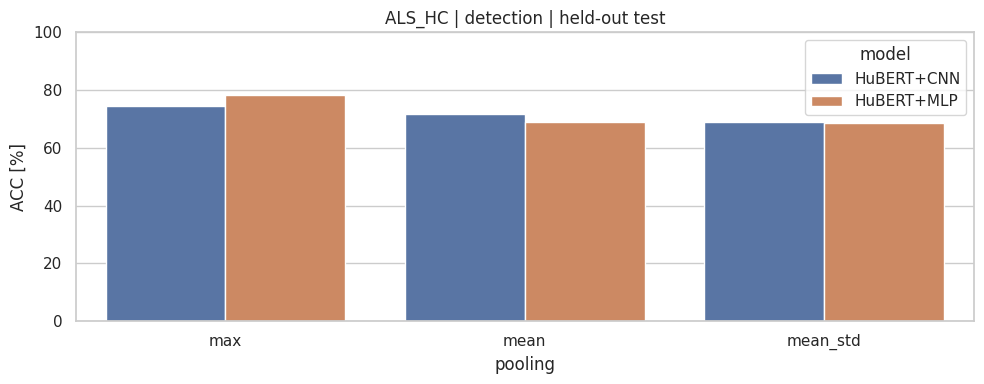

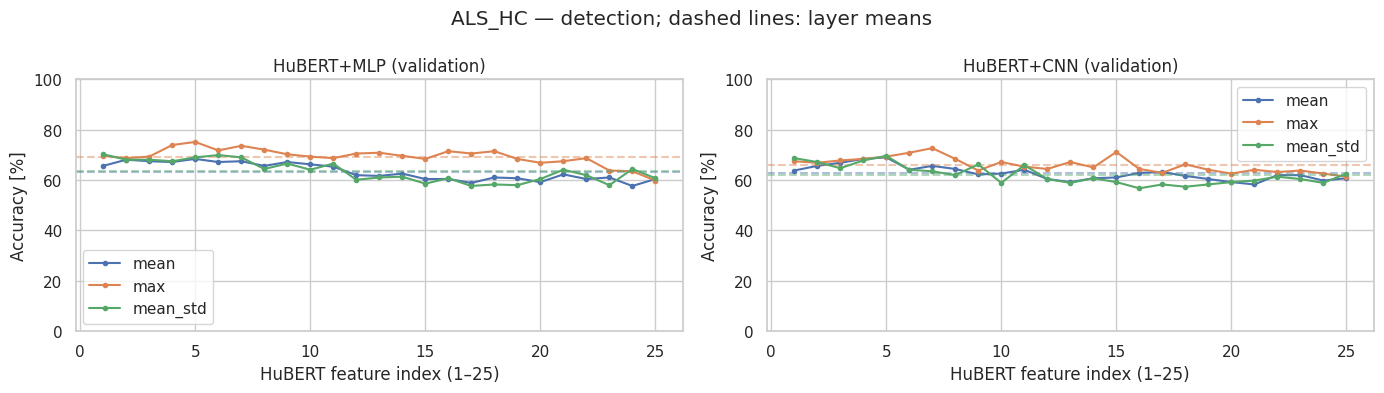

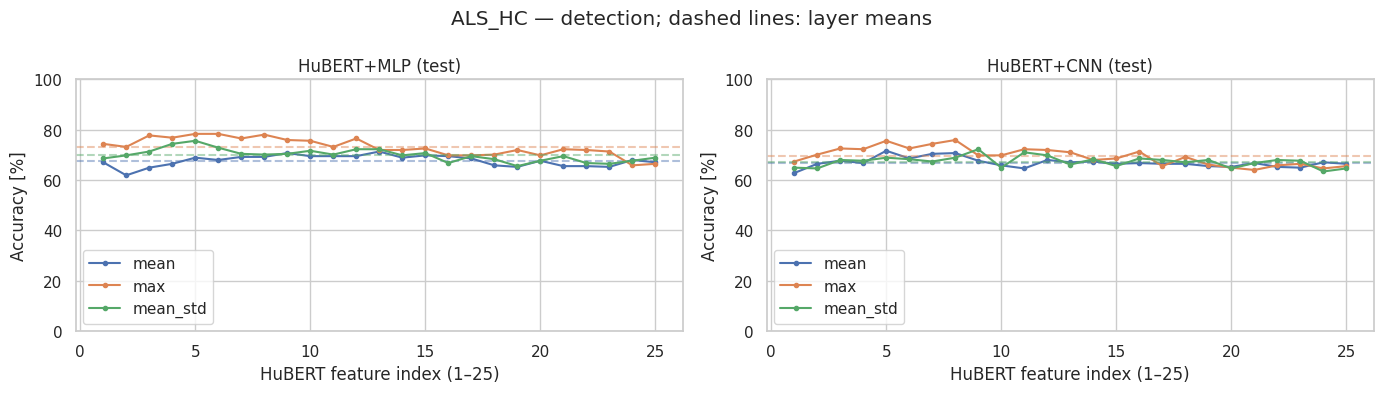

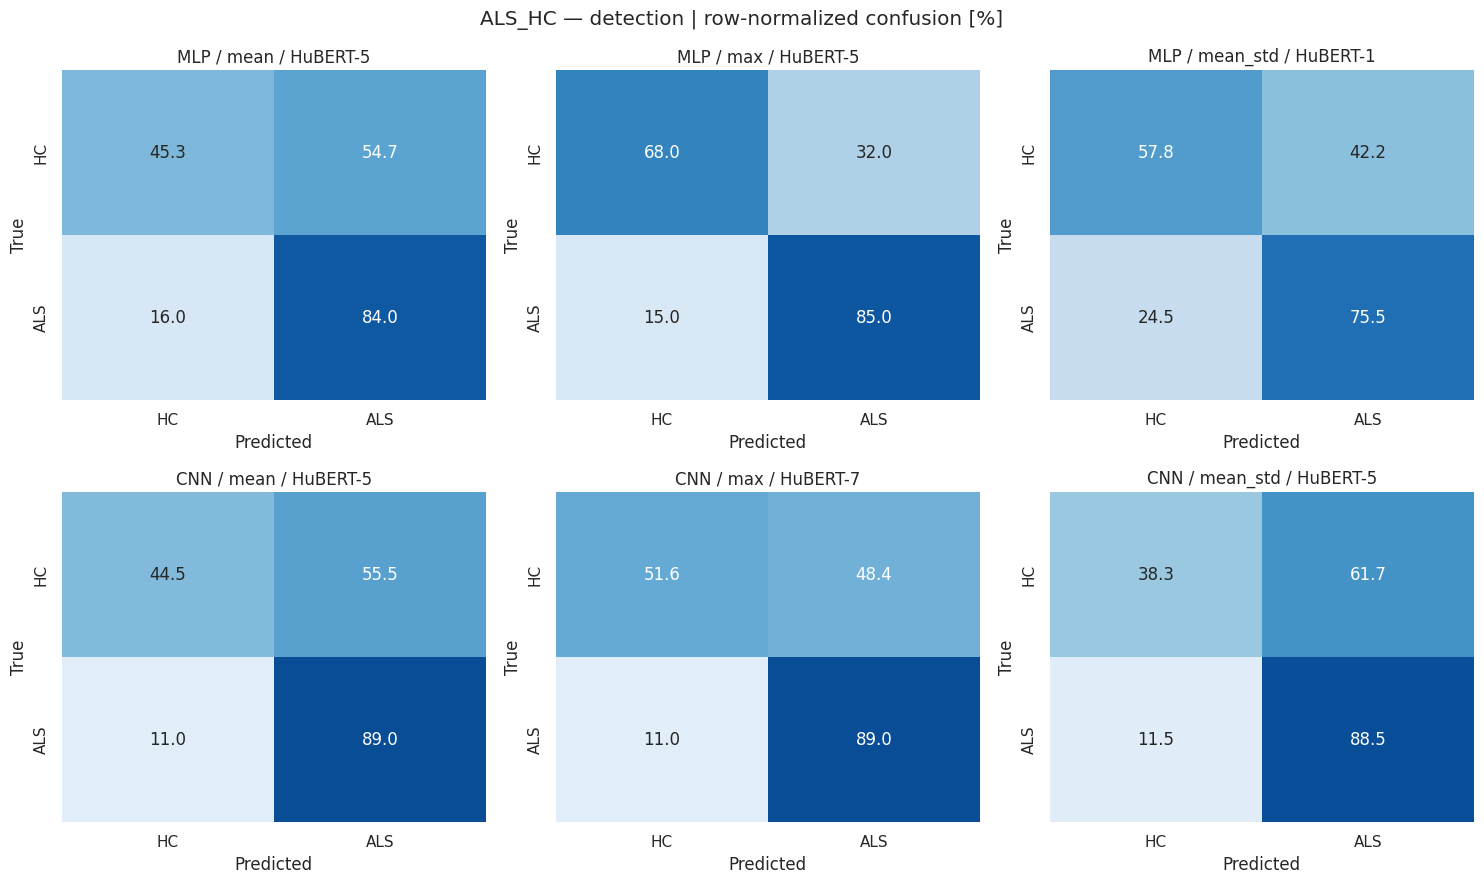

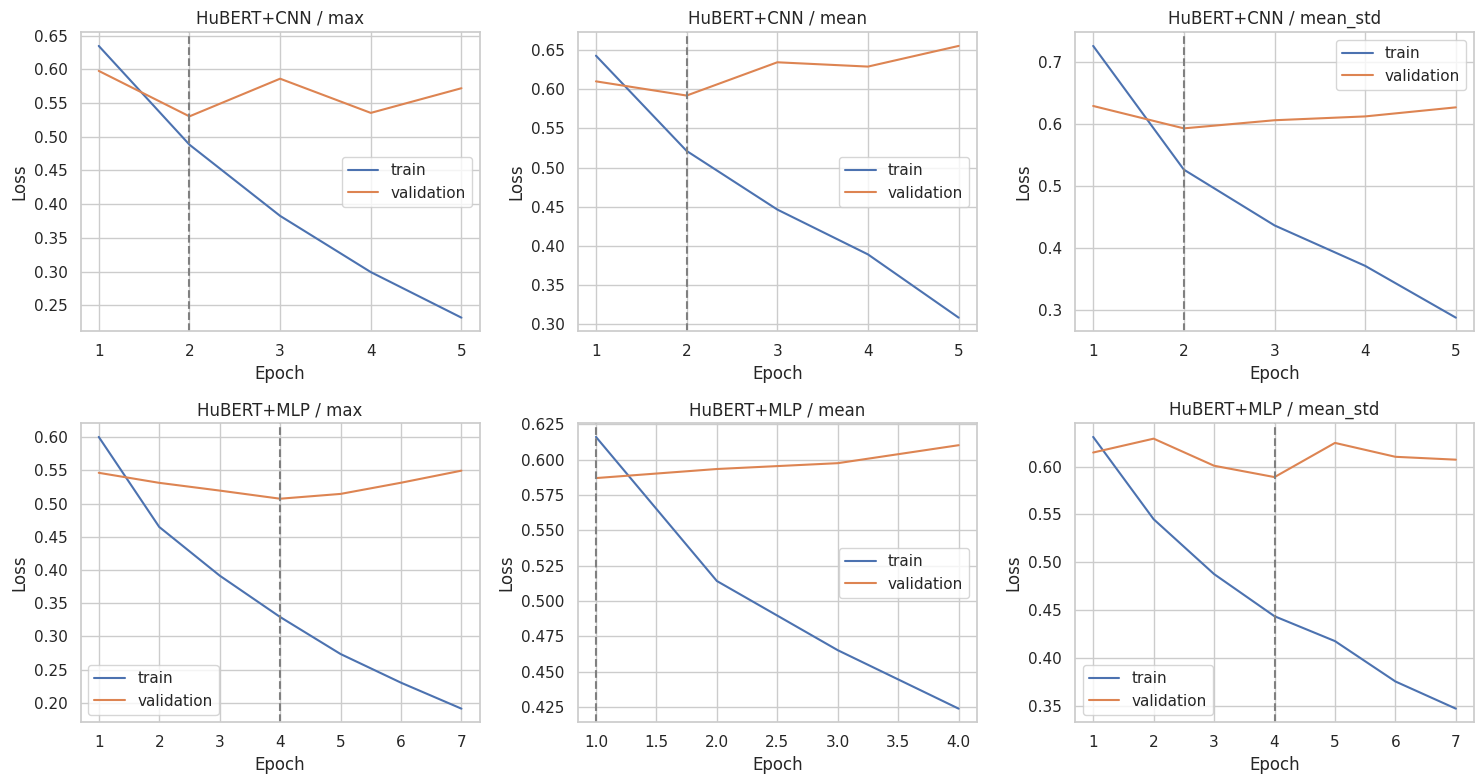

In [ ]:
PLOTS=OUT/'plots'; PLOTS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid',context='notebook')
for (dataset,task),(part,names) in VIEWS.items():
    sub=chosen[(chosen.dataset==dataset)&(chosen.task==task)].sort_values(['model','pooling'])
    slug=hashlib.sha256(dataset.encode()).hexdigest()[:10]+'_'+task
    cols=['model','pooling','paper_layer','ACC [%]']
    cols+=['SE','SP','F1','EER'] if task=='detection' else [f'ACC_{n} [%]' for n in names]
    display(Markdown(f'### {dataset} — {task}: validation-selected layers'))
    display(sub[cols].style.format(precision=3))
    sub[cols].to_csv(OUT/f'{slug}_paper_table.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,4))
    sns.barplot(data=sub,x='pooling',y='ACC [%]',hue='model',ax=ax)
    ax.set_ylim(0,100); ax.set_title(f'{dataset} | {task} | held-out test')
    fig.tight_layout(); fig.savefig(PLOTS/f'{slug}_all_combinations.png',dpi=180); plt.show()
    for split,source,metric in [('validation',validation,'val_ACC'),('test',all_results,'ACC [%]')]:
        fig,axes=plt.subplots(1,len(HEADS),figsize=(14,4),squeeze=False)
        for ax,head in zip(axes.flat,HEADS):
            for pool in POOLINGS:
                line=source[(source.dataset==dataset)&(source.task==task)&(source['head']==head)&(source.pooling==pool)].sort_values('paper_layer')
                artist,=ax.plot(line.paper_layer,line[metric],marker='o',ms=3,label=pool)
                ax.axhline(line[metric].mean(),ls='--',alpha=.45,color=artist.get_color())
            ax.set(title=f'HuBERT+{head} ({split})',xlabel='HuBERT feature index (1–25)',ylabel='Accuracy [%]',ylim=(0,100))
            ax.legend()
        fig.suptitle(f'{dataset} — {task}; dashed lines: layer means')
        fig.tight_layout(); fig.savefig(PLOTS/f'{slug}_{split}_layer_accuracy.png',dpi=180); plt.show()
    fig,axes=plt.subplots(len(HEADS),len(POOLINGS),figsize=(15,9),squeeze=False)
    for i,head in enumerate(HEADS):
        for j,pool in enumerate(POOLINGS):
            r=sub[(sub['head']==head)&(sub.pooling==pool)].iloc[0]
            folder=experiment_dir(dataset,task,head,pool,int(r.hidden_index))
            cm=np.load(folder/'test_confusion_counts.npy')
            normalized=cm/cm.sum(axis=1,keepdims=True)*100
            sns.heatmap(normalized,annot=True,fmt='.1f',cmap='Blues',vmin=0,vmax=100,
                        xticklabels=names,yticklabels=names,ax=axes[i,j],cbar=False)
            axes[i,j].set(title=f'{head} / {pool} / HuBERT-{int(r.paper_layer)}',xlabel='Predicted',ylabel='True')
    fig.suptitle(f'{dataset} — {task} | row-normalized confusion [%]')
    fig.tight_layout(); fig.savefig(PLOTS/f'{slug}_confusions.png',dpi=180); plt.show()
    fig,axes=plt.subplots(2,3,figsize=(15,8))
    for ax,r in zip(axes.flat,sub.itertuples()):
        history=pd.read_csv(experiment_dir(dataset,task,r.head,r.pooling,r.hidden_index)/'history.csv')
        ax.plot(history.epoch,history.train_loss,label='train'); ax.plot(history.epoch,history.val_loss,label='validation')
        ax.axvline(r.best_epoch,color='gray',ls='--'); ax.set(title=f'{r.model} / {r.pooling}',xlabel='Epoch',ylabel='Loss'); ax.legend()
    fig.tight_layout(); fig.savefig(PLOTS/f'{slug}_training_curves.png',dpi=180); plt.show()


In [ ]:
misclassification=[]
for (dataset,task),(part,names) in VIEWS.items():
    if task!='detection': continue
    pred=chosen_predictions[(chosen_predictions.dataset==dataset)&(chosen_predictions.task=='detection')]
    denominator=int(((part.split=='test')&(part.label==1)).sum())
    patients=pred[pred.y_true==1].copy()
    patients['false_negative']=patients.y_pred.eq(0)
    report=patients.groupby(['dataset','model','pooling','paper_layer','speaker_id'],dropna=False).agg(
        patient_test_recordings=('sample_id','size'),misclassified=('false_negative','sum')).reset_index()
    report['percent_of_all_patient_test_recordings']=report.misclassified/denominator*100
    report['denominator_all_patient_test_recordings']=denominator
    misclassification.append(report)
    display(Markdown(f'### {dataset}: Table 5 대응 — 환자 음성의 false negatives'))
    display(report.pivot(index='speaker_id',columns=['model','pooling'],values='misclassified').fillna(0).astype(int))
if misclassification: pd.concat(misclassification).to_csv(OUT/'speaker_misclassification.csv',index=False)
summary=chosen[KEYS+['paper_layer','test_n','test_subjects','ACC [%]']].copy()
summary['protocol']='subject-stratified 70/15/15; validation-selected layer'
summary['backbone']='frozen '+MODEL_ID
summary.to_csv(OUT/'experiment_summary_table6.csv',index=False)
display(Markdown('### Table 6 대응 — 본 실험 요약'))
display(summary)
(OUT/'COMPLETED.json').write_text(json.dumps({'completed_combinations':len(chosen),'completed_layer_runs':len(all_results),'split_hash':SPLIT_HASH},indent=2))
print('모든 활성 과제의 모델 × pooling 조합 평가 완료. 결과 폴더:',OUT)


### ALS_HC: Table 5 대응 — 환자 음성의 false negatives

model      HuBERT+CNN               HuBERT+MLP              
pooling           max mean mean_std        max mean mean_std
speaker_id                                                  
ID026               0    3        0          1    1        3
ID053               0    0        0          0    0        0
ID063               0    0        2          1    1        4
ID069               0    0        0          0    0        0
ID084               0    0        0          1    1        2
ID097               2    0        1          0    1        2
ID104               0    0        0          0    0        0
ID119               5    3        3          3    2        7
ID126               0    0        0          0    0        0
ID127               0    2        1          1    4        5
ID138               0    0        0          0    0        0
ID178               3    4        4          5    3        4
ID185               2    1        1          3    2        2
ID190               2    0        0          0    0        0
ID229               0    0        0          0    0        0
ID231               0    0        0          0    0        1
ID245               5    3        2          8    5        4
ID246               0    1        1          0    1        1
ID247               1    0        0          0    1        1
ID264               0    0        0          0    1        1
ID265               0    0        0          0    0        0
ID266               0    0        0          0    0        0
ID270               0    0        0          0    3        0
ID333               1    3        3          3    2        5
ID338               1    2        5          4    4        7

### Table 6 대응 — 본 실험 요약

,dataset,task,model,pooling,paper_layer,test_n,test_subjects,ACC [%],protocol,backbone
0,ALS_HC,detection,HuBERT+MLP,mean,5,328,41,68.902439,subject-stratified 70/15/15; validation-select...,frozen facebook/hubert-large-ls960-ft
1,ALS_HC,detection,HuBERT+CNN,mean,5,328,41,71.646341,subject-stratified 70/15/15; validation-select...,frozen facebook/hubert-large-ls960-ft
2,ALS_HC,detection,HuBERT+MLP,max,5,328,41,78.353659,subject-stratified 70/15/15; validation-select...,frozen facebook/hubert-large-ls960-ft
3,ALS_HC,detection,HuBERT+CNN,max,7,328,41,74.390244,subject-stratified 70/15/15; validation-select...,frozen facebook/hubert-large-ls960-ft
4,ALS_HC,detection,HuBERT+MLP,mean_std,1,328,41,68.597561,subject-stratified 70/15/15; validation-select...,frozen facebook/hubert-large-ls960-ft
5,ALS_HC,detection,HuBERT+CNN,mean_std,5,328,41,68.902439,subject-stratified 70/15/15; validation-select...,frozen facebook/hubert-large-ls960-ft


모든 활성 과제의 모델 × pooling 조합 평가 완료. 결과 폴더: /content/drive/MyDrive/2026_2_INSIGHT/ALS_RESULTS/ALS_voice_analysis_20260921_075155/HUBERT_PAPER_REPRODUCTION/20261005T080540_357849Z


## 결과 해석 및 출처
- 이 노트북의 test ACC는 발화 단위이며 화자당 발화 수가 다르면 발화가 많은 화자가 더 큰 비중을 가집니다. 화자 단위 분할과 화자 단위 점수 집계는 별개입니다.
- seed를 고정해도 GPU 종류·PyTorch/CUDA 차이로 완전한 bitwise 재현을 보장하지 않습니다. 실행 환경과 모델 revision은 `run_config.json`에 저장됩니다.
- 비교 대상은 동일한 동결 HuBERT 특징의 MLP/CNN 분류기입니다. raw-audio CNN과 HuBERT backbone 간 비교는 아닙니다.
- 데이터와 분할이 원 논문과 다르므로 원 논문 성능과 직접 우열을 결론 내리지 않습니다. 본 논문과의 정확한 수치 재현에는 UA-Speech/TORGO 원본, 마이크 조건, 원 논문 화자 제외/LOSO 프로토콜 등이 추가로 필요합니다.
- [논문](https://doi.org/10.1016/j.specom.2024.103047): §2.1.2 pooling, §2.2 CNN/학습, §3.3 split/z-score, §3.4 metrics, Tables 1–6/Figs. 4–11.
- [Meta HuBERT Large ASR checkpoint](https://huggingface.co/facebook/hubert-large-ls960-ft): checkpoint 출처와 16kHz 입력.
- [Transformers 4.57.1 HuBERT 문서](https://huggingface.co/docs/transformers/v4.57.1/model_doc/hubert): HubertModel과 hidden states.
- [Colab FAQ](https://research.google.com/colaboratory/faq.html): Drive mount 및 런타임 제약.

### 작성 시 검증 범위
노트북 형식·Python 문법, 환자 ID 처리와 분할 누수, pooling 계산, 1024/2048차원 분류기의 역전파, 이진/다중분류 학습·평가, 모든 조합의 표/그래프 생성을 합성 데이터로 검증했습니다. 합성 테스트 수치는 이 노트북에 포함하지 않았습니다. 실제 HuBERT checkpoint 다운로드, 원본 음성의 특징 추출, Colab GPU 전체 학습은 아직 실행하지 않았습니다.
